### Importando as bibliotecas que serão utilizadas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, LinearSVC

from sklearn.metrics import (confusion_matrix, 
    ConfusionMatrixDisplay, 
    accuracy_score,
    precision_score, 
    recall_score, 
    f1_score, 
    classification_report, 
    roc_curve,
    roc_auc_score, 
    auc, 
    precision_recall_curve, 
    average_precision_score
)

RANDOM_STATE = 42
#np.random.seed(RANDOM_STATE)
print("Bibliotecas carregadas!")

Bibliotecas carregadas!


### Lendo o dataset

In [2]:
df = pd.read_csv("../dados/dataset_educacao_desempenho_2000.csv")

df

,idade,horas_estudo_semana,frequencia_percentual,atividades_entregues_percentual,horas_sono,trabalha,deslocamento_minutos,internet_estavel,nota_anterior,participacao_aula,aprovado
0,31,2.0,62.4,49.5,6.3,1,23.9,0,6.1,5.8,0
1,36,16.5,78.9,63.0,6.0,0,37.0,0,7.7,6.9,0
2,43,3.0,88.8,73.8,5.7,0,49.2,1,8.5,5.5,1
3,29,15.7,69.7,71.1,5.0,0,25.9,1,5.0,5.8,0
4,28,17.7,68.1,99.6,5.0,1,10.2,1,7.3,6.8,1
...,...,...,...,...,...,...,...,...,...,...,...
1995,23,11.9,88.2,66.3,6.5,0,143.6,0,6.6,3.9,0
1996,34,10.3,86.7,15.0,5.9,1,69.0,1,6.1,2.7,0
1997,25,1.2,87.4,87.8,7.0,1,25.1,0,6.6,5.0,0
1998,34,14.5,62.2,75.8,8.7,0,7.5,0,3.5,4.1,0


### Informações do dataset

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   idade                            2000 non-null   int64  
 1   horas_estudo_semana              2000 non-null   float64
 2   frequencia_percentual            2000 non-null   float64
 3   atividades_entregues_percentual  2000 non-null   float64
 4   horas_sono                       2000 non-null   float64
 5   trabalha                         2000 non-null   int64  
 6   deslocamento_minutos             2000 non-null   float64
 7   internet_estavel                 2000 non-null   int64  
 8   nota_anterior                    2000 non-null   float64
 9   participacao_aula                2000 non-null   float64
 10  aprovado                         2000 non-null   int64  
dtypes: float64(7), int64(4)
memory usage: 172.0 KB


### Separando X e y

X ficará com as variáveis que usaremos para prever a variável alvo(target) - "aprovado"

In [4]:
X = df.drop(columns=["aprovado"])
y = df["aprovado"]


print("\nDimensão:", df.shape)
print("\nQuantidade por classe:")
print(df["aprovado"].value_counts())
print("\nValores ausentes:", df.isna().sum().sum())


Dimensão: (2000, 11)

Quantidade por classe:
aprovado
0    1338
1     662
Name: count, dtype: int64

Valores ausentes: 0


### Visualização inicial das classes

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste :", X_test.shape)
print("\nDistribuição percentual das classes no treino:")
print(y_train.value_counts(normalize=True).sort_index().round(3))
print("\nDistribuição percentual das classes no teste:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Treino: (1600, 10)
Teste : (400, 10)

Distribuição percentual das classes no treino:
aprovado
0    0.669
1    0.331
Name: proportion, dtype: float64

Distribuição percentual das classes no teste:
aprovado
0    0.67
1    0.33
Name: proportion, dtype: float64


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### SVC linear — parâmetro C

Altere `C_REAL` para comparar o comportamento do classificador.

Sugestões:

`0.01`, `0.1`, `1`, `10`, `100`.

In [7]:
C_REAL = 0.1

svm_real = SVC(
    kernel="linear",
    C=C_REAL,
    decision_function_shape="ovr"
)

svm_real.fit(X_train_scaled, y_train)

y_pred_r = svm_real.predict(X_test_scaled)
y_score_r = svm_real.decision_function(X_test_scaled)

print(svm_real)
print("Número de vetores de suporte por classe:", svm_real.n_support_)
print("Total de vetores de suporte:", len(svm_real.support_vectors_))

SVC(C=0.1, kernel='linear')
Número de vetores de suporte por classe: [496 494]
Total de vetores de suporte: 990


### Matriz de confusão

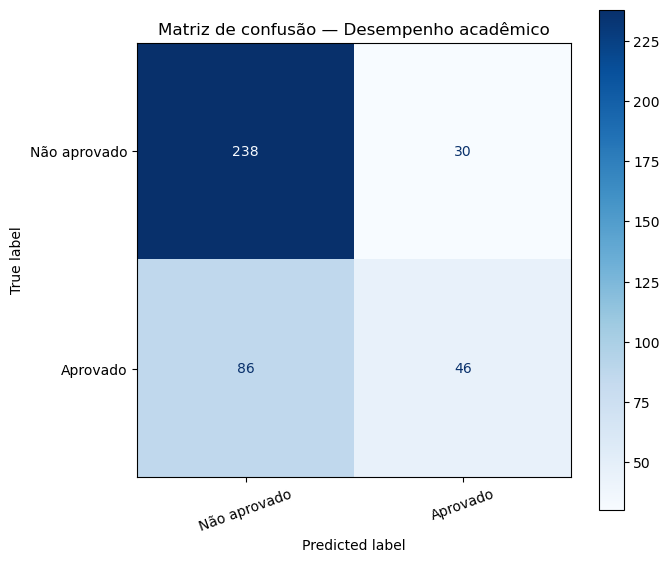

In [8]:
cm_r = confusion_matrix(y_test, y_pred_r)

fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(
    confusion_matrix=cm_r,
    display_labels=["Não aprovado", "Aprovado"]
).plot(ax=ax, cmap="Blues", values_format="d")

plt.title(f"Matriz de confusão — Desempenho acadêmico")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Métricas gerais

In [9]:
accuracy_r = accuracy_score(y_test, y_pred_r)
precision_macro = precision_score(y_test, y_pred_r, average="macro", zero_division=0)
recall_macro = recall_score(y_test, y_pred_r, average="macro", zero_division=0)
f1_macro = f1_score(y_test, y_pred_r, average="macro", zero_division=0)
#specificity_macro = metricas_classes["Especificidade"].mean()

metricas_gerais = pd.DataFrame({
    "Métrica":[
        "Accuracy",
        "Precision macro",
        "Recall macro",
        #"Especificidade macro",
        "F1 macro"
    ],
    "Valor":[
        accuracy_r,
        precision_macro,
        recall_macro,
        #specificity_macro,
        f1_macro
    ]
})

display(metricas_gerais.style.format({"Valor":"{:.4f}"}))

print("\nRelatório por classe:\n")
print(classification_report(
    y_test,
    y_pred_r,
    target_names=["Não aprovado", "Aprovado"],
    zero_division=0
))

,Métrica,Valor
0,Accuracy,0.7100
1,Precision macro,0.6699
2,Recall macro,0.6183
3,F1 macro,0.6232



Relatório por classe:

              precision    recall  f1-score   support

Não aprovado       0.73      0.89      0.80       268
    Aprovado       0.61      0.35      0.44       132

    accuracy                           0.71       400
   macro avg       0.67      0.62      0.62       400
weighted avg       0.69      0.71      0.68       400



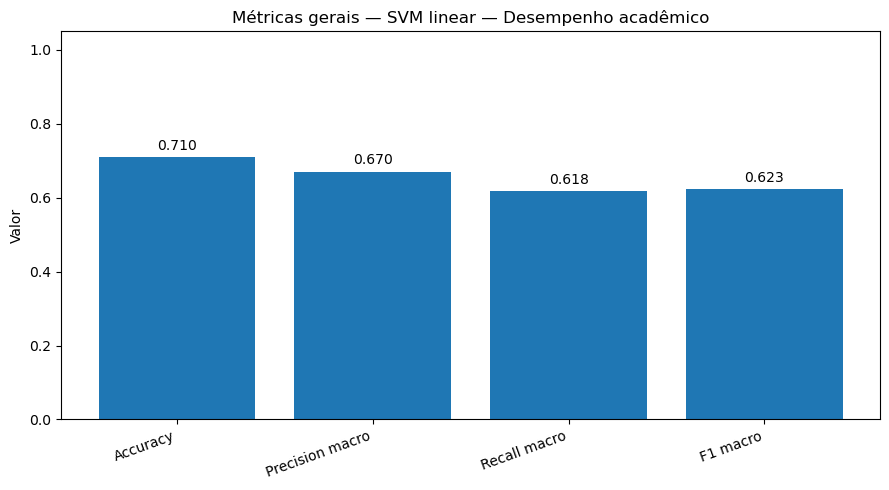

In [10]:
plt.figure(figsize=(9,5))
plt.bar(metricas_gerais["Métrica"], metricas_gerais["Valor"])
plt.ylim(0,1.05)
plt.ylabel("Valor")
plt.title(f"Métricas gerais — SVM linear — Desempenho acadêmico")
plt.xticks(rotation=20, ha="right")

for i, valor in enumerate(metricas_gerais["Valor"]):
    plt.text(i, valor+0.02, f"{valor:.3f}", ha="center")

plt.tight_layout()
plt.show()

### Curva ROC e AUC

AUC ROC = 0.7255


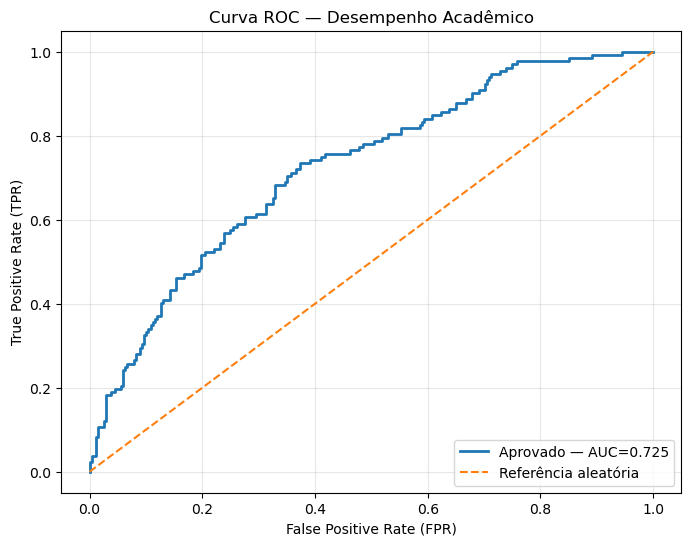

In [11]:
nomes_classes = {
    0: "Não aprovado",
    1: "Aprovado"
}

classes_r = np.unique(np.array(y))
n_classes_r = len(classes_r)

plt.figure(figsize=(8,6))

if n_classes_r == 2:
    # decision_function retorna um score para a classe positiva
    fpr, tpr, _ = roc_curve(y_test, y_score_r)
    auc_roc = roc_auc_score(y_test, y_score_r)

    plt.plot(fpr, tpr, linewidth=2,
             label=f"{nomes_classes[1]} — AUC={auc_roc:.3f}")
    print(f"AUC ROC = {auc_roc:.4f}")

else:
    y_test_bin = label_binarize(y_test, classes=classes_r)

    aucs = []
    for i, classe in enumerate(classes_r):
        fpr, tpr, _ = roc_curve(y_test_bin[:,i], y_score_r[:,i])
        auc_i = auc(fpr,tpr)
        aucs.append(auc_i)
        plt.plot(
            fpr,tpr,linewidth=2,
            label=f"{nomes_classes[classe]} — AUC={auc_i:.3f}"
        )

    auc_macro = roc_auc_score(
        y_test_bin,
        y_score_r,
        average="macro",
        multi_class="ovr"
    )
    print(f"AUC ROC macro (OvR) = {auc_macro:.4f}")

plt.plot([0,1],[0,1],linestyle="--",label="Referência aleatória")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title(f"Curva ROC — Desempenho Acadêmico")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

### Interpretação da Curva ROC e da AUC

A curva ROC (*Receiver Operating Characteristic*) é utilizada para avaliar a capacidade de um modelo de classificação binária de distinguir as classes para diferentes limiares de decisão. Ela relaciona a taxa de verdadeiros positivos (TPR), equivalente ao recall da classe positiva, com a taxa de falsos positivos (FPR).

A AUC (*Area Under the Curve*) representa a área abaixo da curva ROC e resume a capacidade de discriminação do modelo. Valores próximos de 0,5 indicam desempenho semelhante ao de um classificador aleatório, enquanto valores próximos de 1,0 indicam maior capacidade de separar as classes.

Neste experimento, o SVM Linear obteve **AUC ROC de 0,725**, indicando uma capacidade de discriminação superior à referência aleatória. Observando o gráfico, verificamos que a curva ROC permanece, em grande parte, acima da diagonal de referência, reforçando que o modelo consegue distinguir as classes melhor do que uma classificação aleatória.

Apesar desse resultado positivo, a AUC não representa a porcentagem de previsões corretas e não garante que o modelo tenha bom desempenho em todas as métricas. Por isso, ela deve ser analisada em conjunto com a acurácia, a precisão, o recall e o F1-score, especialmente para verificar o desempenho na identificação dos alunos aprovados.

**Conclusão:** a AUC de 0,725 indica que o SVM Linear apresenta uma capacidade razoável de distinguir as classes neste conjunto de teste, mas ainda existe espaço para melhorias. A avaliação final do modelo deverá considerar também as demais métricas e sua comparação com o KNN.

## Curva Precision–Recall e Average Precision

Average Precision = 0.5648


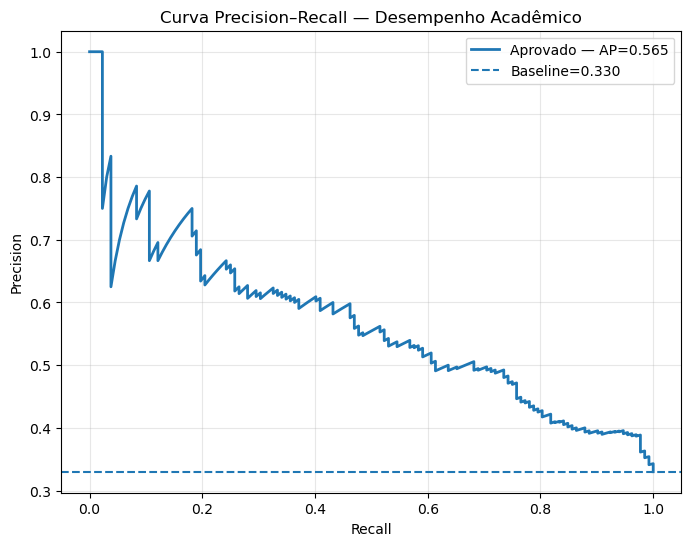

In [12]:
plt.figure(figsize=(8,6))

if n_classes_r == 2:
    precision_curve, recall_curve, _ = precision_recall_curve(
        y_test, y_score_r
    )
    ap = average_precision_score(y_test, y_score_r)

    plt.plot(
        recall_curve, precision_curve,
        linewidth=2,
        label=f"{nomes_classes[1]} — AP={ap:.3f}"
    )

    baseline = np.mean(y_test)
    plt.axhline(
        baseline,
        linestyle="--",
        label=f"Baseline={baseline:.3f}"
    )

    print(f"Average Precision = {ap:.4f}")

else:
    y_test_bin = label_binarize(y_test, classes=classes_r)
    aps = []

    for i, classe in enumerate(classes_r):
        precision_curve, recall_curve, _ = precision_recall_curve(
            y_test_bin[:,i],
            y_score_r[:,i]
        )

        ap_i = average_precision_score(
            y_test_bin[:,i],
            y_score_r[:,i]
        )

        aps.append(ap_i)

        plt.plot(
            recall_curve,
            precision_curve,
            linewidth=2,
            label=f"{nomes_classes[classe]} — AP={ap_i:.3f}"
        )

    print(f"Average Precision macro = {np.mean(aps):.4f}")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Curva Precision–Recall — Desempenho Acadêmico")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Interpretação da Curva Precision–Recall e do Average Precision

A curva Precision–Recall permite avaliar o desempenho de um modelo de classificação considerando a relação entre duas métricas: **precision**, que indica a proporção de previsões positivas que estão corretas, e **recall**, que representa a proporção de exemplos positivos reais identificados pelo modelo.

O **Average Precision (AP)** resume o desempenho da relação entre precision e recall ao longo dos diferentes limiares de decisão. Quanto maior seu valor, melhor tende a ser a capacidade do modelo de recuperar exemplos da classe positiva mantendo uma boa precisão.

Neste experimento, o SVM Linear obteve **Average Precision de 0,5646** para a classe “Aprovado”. Esse resultado está acima da linha de referência (*baseline*), que corresponde à proporção de alunos aprovados no conjunto de teste, aproximadamente 0,33. Isso indica que o modelo consegue identificar padrões associados à classe “Aprovado” melhor do que uma referência simples baseada na frequência dessa classe.

Entretanto, o resultado ainda indica espaço para melhorias. No relatório de classificação, o recall da classe “Aprovado” foi de 0,35, mostrando que, no limiar de decisão utilizado pelo modelo, apenas 35% dos alunos realmente aprovados foram identificados corretamente. Isso não contradiz o AP, pois a curva Precision–Recall avalia o comportamento do modelo em diferentes limiares, enquanto o relatório considera as previsões em um limiar específico.

**Conclusão:** o Average Precision de 0,5646 sugere que o SVM Linear apresenta capacidade útil de identificar alunos aprovados, mas ainda possui limitações. Por isso, esse resultado deve ser analisado em conjunto com a acurácia, o recall, o F1-score e a AUC ROC. Nos próximos experimentos, serão avaliados diferentes valores do parâmetro \(C\), buscando melhorar o desempenho do modelo antes de considerar técnicas adicionais, como o balanceamento de classes.

### Comparando diferentes valores de C no dataset selecionado

Agora repetiremos o treinamento com diferentes valores de `C`.

Observe principalmente:

- desempenho de treino;
- desempenho de teste;
- Precision;
- Recall;
- Especificidade;
- F1;
- número de vetores de suporte.

In [13]:
resultados_c_real = []

for c in [0.001, 0.01, 0.1, 1, 10, 100]:
    m = SVC(kernel="linear", C=c, decision_function_shape="ovr")
    m.fit(X_train_scaled, y_train)

    pred_c = m.predict(X_test_scaled)
    cm_c = confusion_matrix(y_test, pred_c)

    especificidades = []
    for i in range(len(classes_r)):
        vp = cm_c[i,i]
        fn = cm_c[i,:].sum()-vp
        fp = cm_c[:,i].sum()-vp
        vn = cm_c.sum()-vp-fn-fp
        especificidades.append(vn/(vn+fp) if (vn+fp) else 0)

    resultados_c_real.append({
        "C":c,
        "Accuracy_treino":m.score(X_train_scaled,y_train),
        "Accuracy_teste":accuracy_score(y_test,pred_c),
        "Precision_macro":precision_score(y_test,pred_c,average="macro",zero_division=0),
        "Recall_macro":recall_score(y_test,pred_c,average="macro",zero_division=0),
        "Especificidade_macro":np.mean(especificidades),
        "F1_macro":f1_score(y_test,pred_c,average="macro",zero_division=0),
        "Vetores_suporte":len(m.support_vectors_)
    })

comparacao_c_real = pd.DataFrame(resultados_c_real)

display(comparacao_c_real.style.format({
    "Accuracy_treino":"{:.4f}",
    "Accuracy_teste":"{:.4f}",
    "Precision_macro":"{:.4f}",
    "Recall_macro":"{:.4f}",
    "Especificidade_macro":"{:.4f}",
    "F1_macro":"{:.4f}"
}))

,C,Accuracy_treino,Accuracy_teste,Precision_macro,Recall_macro,Especificidade_macro,F1_macro,Vetores_suporte
0,0.001000,0.6687,0.6700,0.3350,0.5000,0.5000,0.4012,1064
1,0.010000,0.7262,0.7050,0.6686,0.5972,0.5972,0.5957,1049
2,0.100000,0.7381,0.7100,0.6699,0.6183,0.6183,0.6232,990
3,1.000000,0.7388,0.7100,0.6699,0.6183,0.6183,0.6232,982
4,10.000000,0.7381,0.7100,0.6699,0.6183,0.6183,0.6232,979
5,100.000000,0.7388,0.7100,0.6699,0.6183,0.6183,0.6232,979


Minha escolha seria \(C=0,1\)
Por quê?
- Apresenta a maior acurácia de teste, empatada com os valores \(1\), \(10\) e \(100\).
- Empata pelo maior recall macro, precision macro e F1 macro.
- Tem desempenho de treino semelhante aos outros valores a partir de \(C=0,1\).
- É o menor valor de \(C\) entre as configurações que alcançaram esses resultados, o que favorece escolhê-lo como uma configuração mais regularizada, sem perda observada nas métricas.

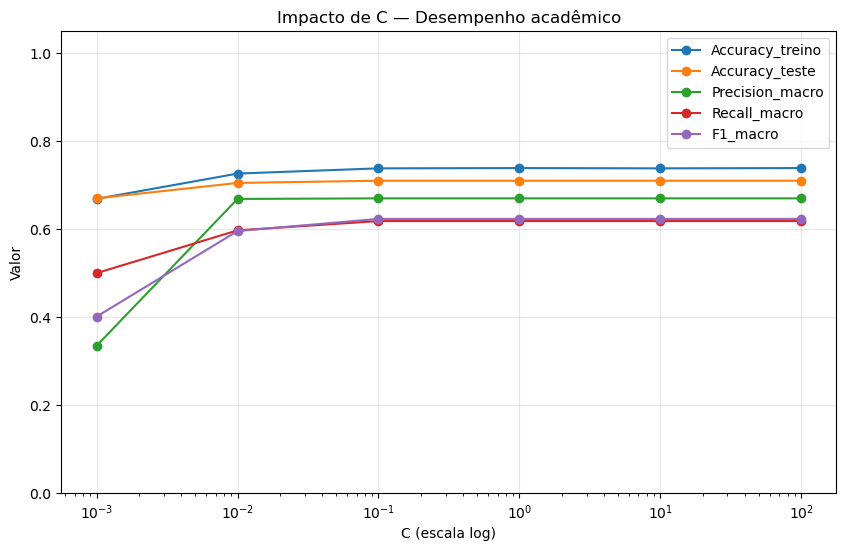

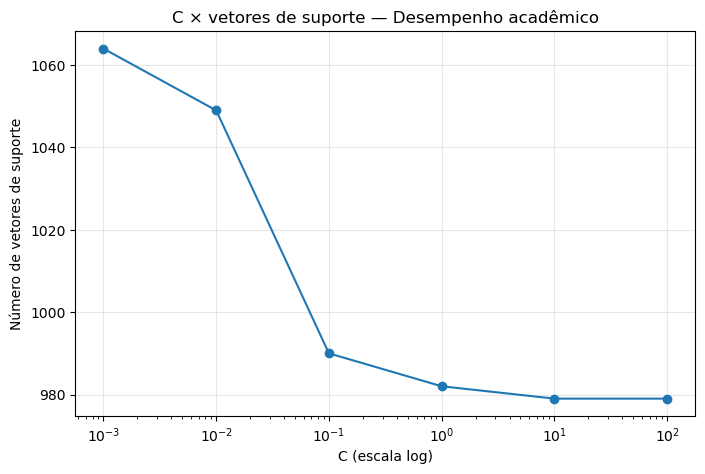

In [14]:
plt.figure(figsize=(10,6))

for metrica in [
    "Accuracy_treino",
    "Accuracy_teste",
    "Precision_macro",
    "Recall_macro",
    "F1_macro"
]:
    plt.semilogx(
        comparacao_c_real["C"],
        comparacao_c_real[metrica],
        marker="o",
        label=metrica
    )

plt.ylim(0,1.05)
plt.xlabel("C (escala log)")
plt.ylabel("Valor")
plt.title(f"Impacto de C — Desempenho acadêmico")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8,5))
plt.semilogx(
    comparacao_c_real["C"],
    comparacao_c_real["Vetores_suporte"],
    marker="o"
)
plt.xlabel("C (escala log)")
plt.ylabel("Número de vetores de suporte")
plt.title(f"C × vetores de suporte — Desempenho acadêmico")
plt.grid(alpha=0.3)
plt.show()

### Interpretação dos resultados do SVM Linear

Após testar diferentes valores do parâmetro \(C\), selecionamos \(C=0,1\) como candidato, pois apresentou os melhores resultados observados nas métricas de teste, empatando com valores maiores de \(C\).

O modelo obteve **acurácia de 71%**, recall macro de 0,62 e F1-score macro de 0,62. Entretanto, a análise por classe revelou uma diferença importante: o recall foi de 0,89 para “Não aprovado” e de apenas 0,35 para “Aprovado”.

Esses resultados indicam que o SVM Linear identifica melhor os alunos não aprovados, mas apresenta dificuldade para reconhecer os alunos aprovados. Portanto, a acurácia isolada não é suficiente para avaliar o desempenho do modelo.

Na comparação inicial com o KNN de \(k=3\), o SVM apresentou maior acurácia, enquanto o KNN obteve recall superior para a classe “Aprovado”. As métricas macro foram próximas, indicando que os dois modelos possuem vantagens e limitações distintas.

**Conclusão:** o SVM Linear com \(C=0,1\) é um candidato promissor entre as configurações testadas, mas ainda apresenta desempenho desigual entre as classes.

## Agora passando para o kernel "rbf" para testar o gamma

### SVC RBF — grade de C × gamma

No kernel linear só o `C` importa. No kernel RBF o `gamma` define o alcance de influência de cada vetor de suporte:

- **gamma pequeno** → fronteira suave (tende a subajuste, aproxima-se de um modelo linear);
- **gamma grande** → fronteira muito flexível, cada ponto tem influência local (tende a sobreajuste).

Valores pedidos: **C** = 0,01; 0,1; 1; 10; 100 e **gamma** = 0,001; 0,01; 0,1; 1; 10. Os 25 pares são treinados com os mesmos dados padronizados usados no SVM linear (`X_train_scaled` / `X_test_scaled`).

In [15]:
valores_c = [0.01, 0.1, 1, 10, 100]
valores_gamma = [0.001, 0.01, 0.1, 1, 10]

resultados_rbf = []

for c in valores_c:
    for g in valores_gamma:
        m = SVC(kernel="rbf", C=c, gamma=g)
        m.fit(X_train_scaled, y_train)

        pred_g = m.predict(X_test_scaled)

        resultados_rbf.append({
            "C": c,
            "Gamma": g,
            "Accuracy_treino": m.score(X_train_scaled, y_train),
            "Accuracy_teste": accuracy_score(y_test, pred_g),
            "Precision_macro": precision_score(y_test, pred_g, average="macro", zero_division=0),
            "Recall_macro": recall_score(y_test, pred_g, average="macro", zero_division=0),
            "F1_macro": f1_score(y_test, pred_g, average="macro", zero_division=0),
            "Recall_Aprovado": recall_score(y_test, pred_g, pos_label=1, zero_division=0),
            "Vetores_suporte": len(m.support_vectors_)
        })

comparacao_rbf = pd.DataFrame(resultados_rbf)

formato_rbf = {
    "Accuracy_treino": "{:.4f}",
    "Accuracy_teste": "{:.4f}",
    "Precision_macro": "{:.4f}",
    "Recall_macro": "{:.4f}",
    "F1_macro": "{:.4f}",
    "Recall_Aprovado": "{:.4f}"
}

display(
    comparacao_rbf
    .sort_values(by="F1_macro", ascending=False)
    .reset_index(drop=True)
    .style.format(formato_rbf)
)

,C,Gamma,Accuracy_treino,Accuracy_teste,Precision_macro,Recall_macro,F1_macro,Recall_Aprovado,Vetores_suporte
0,10.000000,0.100000,0.8781,0.6850,0.6373,0.6265,0.6302,0.4545,1012
1,100.000000,0.001000,0.7400,0.7150,0.6780,0.6239,0.6297,0.3561,987
2,10.000000,0.010000,0.7462,0.7150,0.6835,0.6143,0.6174,0.3182,981
3,1.000000,0.010000,0.7319,0.7075,0.6676,0.6106,0.6138,0.3258,1030
4,100.000000,0.100000,0.9775,0.6625,0.6149,0.6117,0.6130,0.4621,904
5,1.000000,0.100000,0.7825,0.7125,0.6810,0.6086,0.6101,0.3030,1044
6,100.000000,0.010000,0.7606,0.7100,0.6756,0.6067,0.6081,0.3030,958
7,10.000000,0.001000,0.7331,0.7000,0.6562,0.5974,0.5973,0.2955,1024
8,0.100000,0.100000,0.7069,0.6950,0.7012,0.5513,0.5143,0.1288,1099
9,100.000000,1.000000,1.0000,0.6450,0.5125,0.5044,0.4603,0.0909,1598


#### Impacto de gamma para cada valor de C

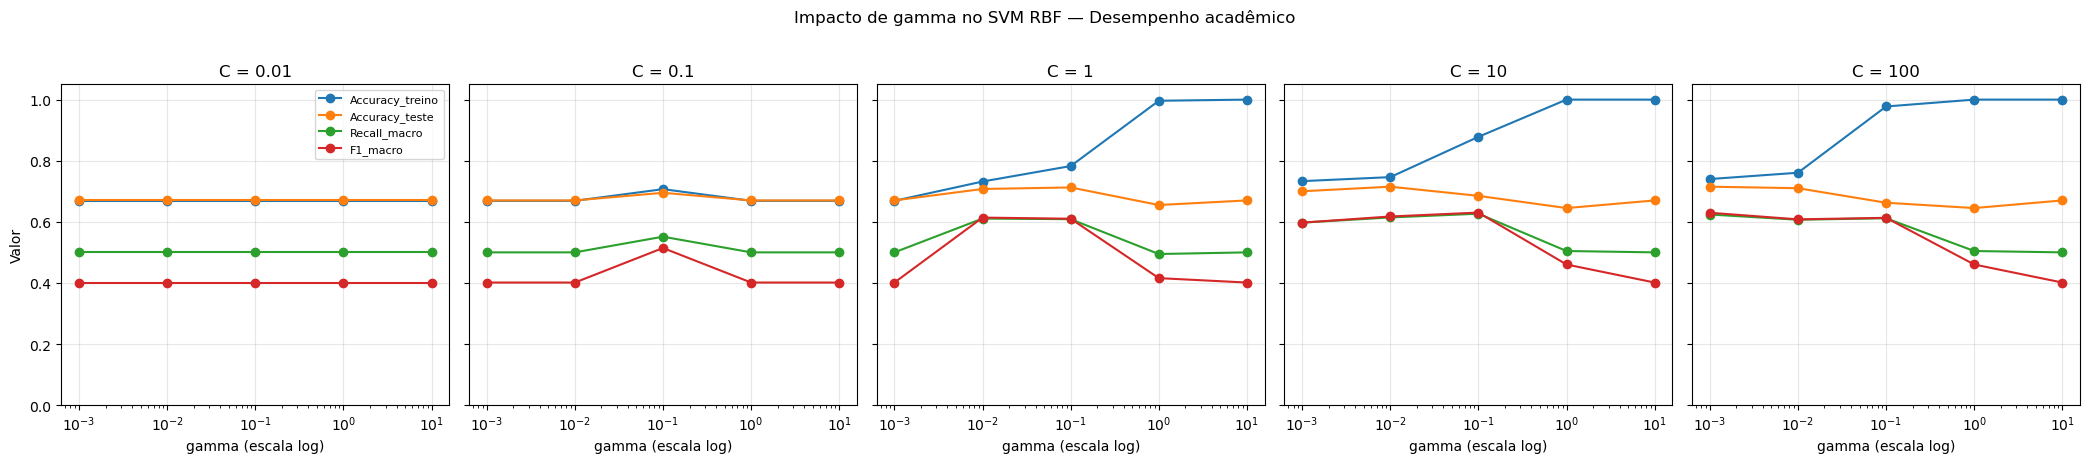

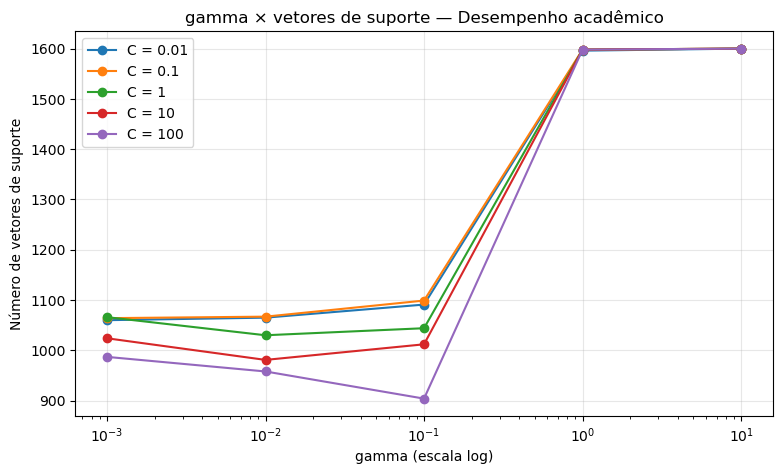

In [16]:
fig, axes = plt.subplots(1, len(valores_c), figsize=(4.2*len(valores_c), 4.5), sharey=True)

for ax, c in zip(axes, valores_c):
    sub = comparacao_rbf[comparacao_rbf["C"] == c]
    for metrica in ["Accuracy_treino", "Accuracy_teste", "Recall_macro", "F1_macro"]:
        ax.semilogx(sub["Gamma"], sub[metrica], marker="o", label=metrica)
    ax.set_title(f"C = {c}")
    ax.set_xlabel("gamma (escala log)")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Valor")
axes[0].legend(fontsize=8)
fig.suptitle("Impacto de gamma no SVM RBF — Desempenho acadêmico", y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,5))
for c in valores_c:
    sub = comparacao_rbf[comparacao_rbf["C"] == c]
    plt.semilogx(sub["Gamma"], sub["Vetores_suporte"], marker="o", label=f"C = {c}")
plt.xlabel("gamma (escala log)")
plt.ylabel("Número de vetores de suporte")
plt.title("gamma × vetores de suporte — Desempenho acadêmico")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Mapas de calor C × gamma

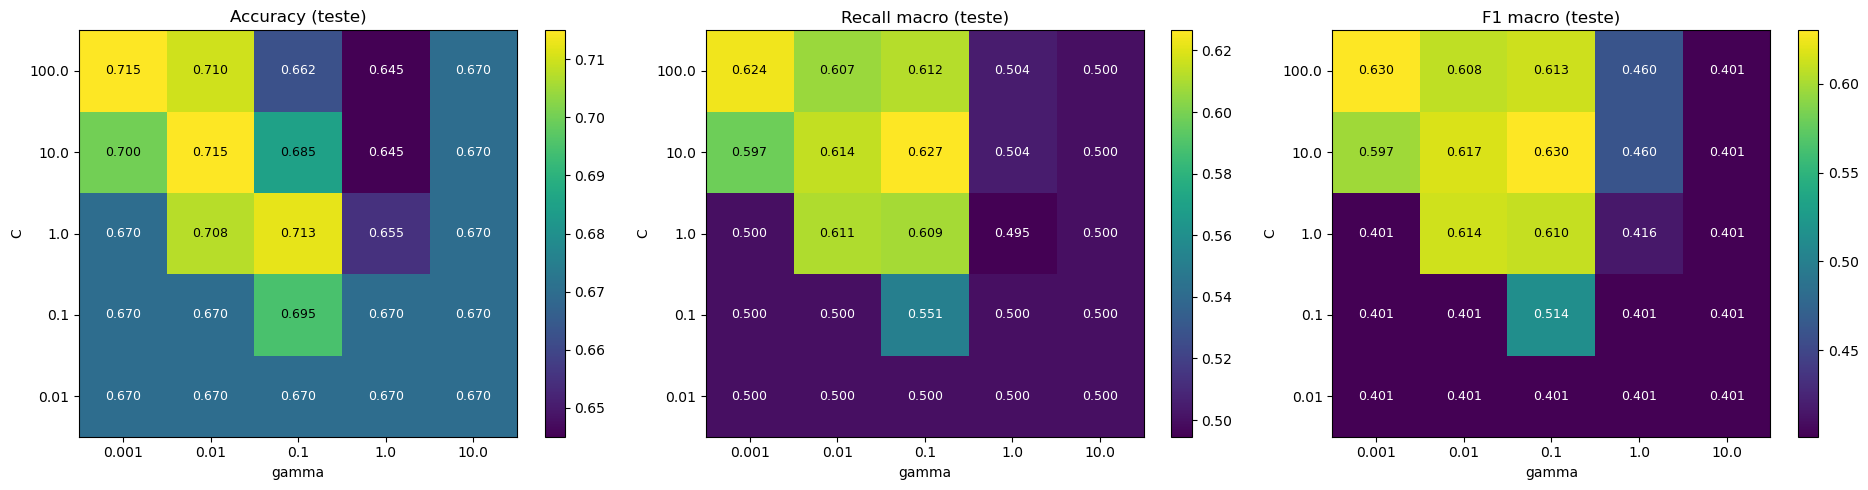

In [17]:
def mapa_calor(ax, coluna, titulo):
    tabela = comparacao_rbf.pivot(index="C", columns="Gamma", values=coluna)
    im = ax.imshow(tabela.values, cmap="viridis", aspect="auto", origin="lower")
    ax.set_xticks(range(len(tabela.columns)))
    ax.set_xticklabels(tabela.columns)
    ax.set_yticks(range(len(tabela.index)))
    ax.set_yticklabels(tabela.index)
    ax.set_xlabel("gamma")
    ax.set_ylabel("C")
    ax.set_title(titulo)
    limite = (tabela.values.min() + tabela.values.max()) / 2
    for i in range(tabela.shape[0]):
        for j in range(tabela.shape[1]):
            v = tabela.values[i, j]
            ax.text(j, i, f"{v:.3f}", ha="center", va="center",
                    color="white" if v < limite else "black", fontsize=9)
    plt.colorbar(im, ax=ax)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
mapa_calor(axes[0], "Accuracy_teste", "Accuracy (teste)")
mapa_calor(axes[1], "Recall_macro", "Recall macro (teste)")
mapa_calor(axes[2], "F1_macro", "F1 macro (teste)")
plt.tight_layout()
plt.show()

### Melhor combinação (C, gamma) e avaliação detalhada

Critério: maior **F1 macro** no teste (as classes são desbalanceadas, então a acurácia sozinha favorece o modelo que só prevê a classe majoritária). Em empate, usa-se a maior acurácia de teste.

Observação metodológica: escolher os hiperparâmetros olhando o conjunto de teste torna a métrica final levemente otimista. O mesmo critério já foi usado na escolha de C no kernel linear.

SVC(C=10.0, gamma=0.1)
Número de vetores de suporte por classe: [560 452]
Total de vetores de suporte: 1012


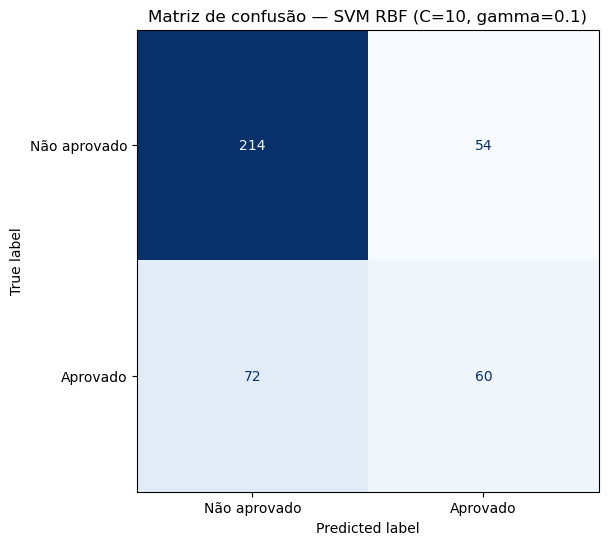


Relatório por classe:

              precision    recall  f1-score   support

Não aprovado       0.75      0.80      0.77       268
    Aprovado       0.53      0.45      0.49       132

    accuracy                           0.69       400
   macro avg       0.64      0.63      0.63       400
weighted avg       0.68      0.69      0.68       400



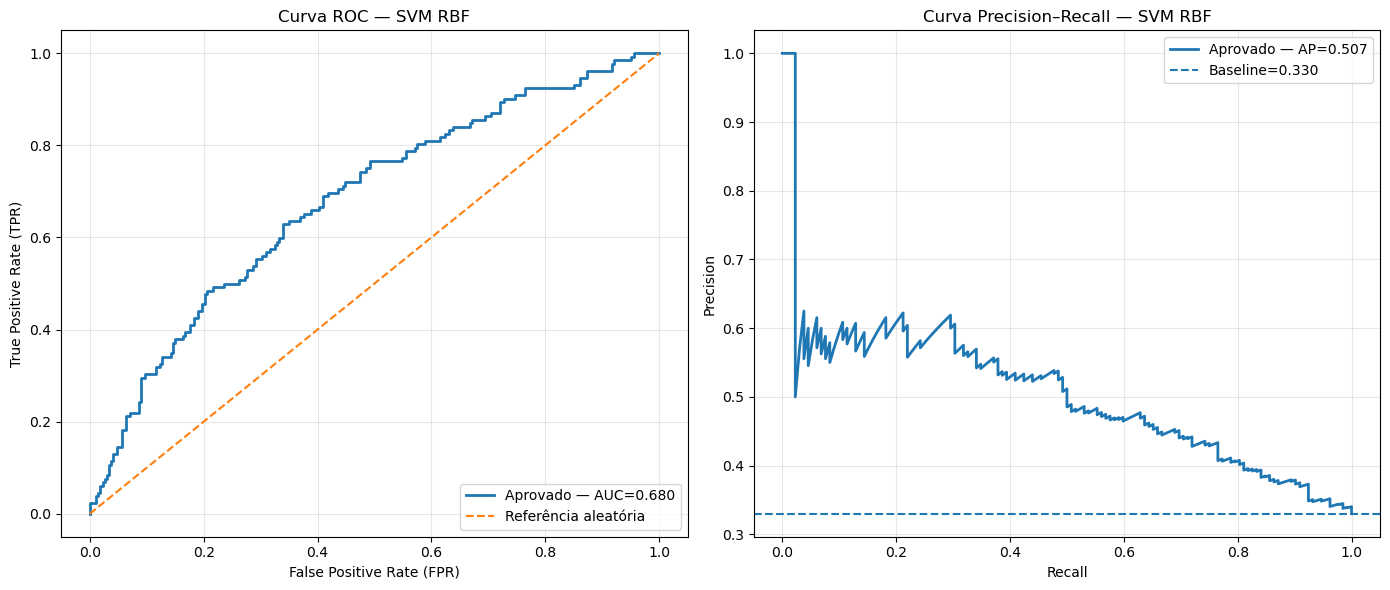

AUC ROC = 0.6799
Average Precision = 0.5070


In [18]:
melhor = (
    comparacao_rbf
    .sort_values(by=["F1_macro", "Accuracy_teste"], ascending=False)
    .iloc[0]
)

C_RBF = float(melhor["C"])
GAMMA_RBF = float(melhor["Gamma"])

svm_rbf = SVC(kernel="rbf", C=C_RBF, gamma=GAMMA_RBF)
svm_rbf.fit(X_train_scaled, y_train)

y_pred_rbf = svm_rbf.predict(X_test_scaled)
y_score_rbf = svm_rbf.decision_function(X_test_scaled)

print(svm_rbf)
print("Número de vetores de suporte por classe:", svm_rbf.n_support_)
print("Total de vetores de suporte:", len(svm_rbf.support_vectors_))

cm_rbf = confusion_matrix(y_test, y_pred_rbf)
fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(cm_rbf, display_labels=["Não aprovado", "Aprovado"]).plot(
    ax=ax, cmap="Blues", colorbar=False
)
ax.set_title(f"Matriz de confusão — SVM RBF (C={C_RBF:g}, gamma={GAMMA_RBF:g})")
plt.show()

print("\nRelatório por classe:\n")
print(classification_report(
    y_test, y_pred_rbf,
    target_names=["Não aprovado", "Aprovado"],
    zero_division=0
))

fpr_rbf, tpr_rbf, _ = roc_curve(y_test, y_score_rbf)
auc_rbf = roc_auc_score(y_test, y_score_rbf)

prec_rbf, rec_rbf, _ = precision_recall_curve(y_test, y_score_rbf)
ap_rbf = average_precision_score(y_test, y_score_rbf)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].plot(fpr_rbf, tpr_rbf, linewidth=2, label=f"Aprovado — AUC={auc_rbf:.3f}")
axes[0].plot([0,1], [0,1], linestyle="--", label="Referência aleatória")
axes[0].set_xlabel("False Positive Rate (FPR)")
axes[0].set_ylabel("True Positive Rate (TPR)")
axes[0].set_title("Curva ROC — SVM RBF")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

axes[1].plot(rec_rbf, prec_rbf, linewidth=2, label=f"Aprovado — AP={ap_rbf:.3f}")
axes[1].axhline(np.mean(y_test), linestyle="--", label=f"Baseline={np.mean(y_test):.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Curva Precision–Recall — SVM RBF")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"AUC ROC = {auc_rbf:.4f}")
print(f"Average Precision = {ap_rbf:.4f}")

### Comparação final: SVM linear × SVM RBF

,Modelo,Accuracy,Precision_macro,Recall_macro,F1_macro,Recall_Aprovado,AUC,AP
0,Linear (C=0.1),0.7100,0.6699,0.6183,0.6232,0.3485,0.7255,0.5648
1,"RBF (C=10, gamma=0.1)",0.6850,0.6373,0.6265,0.6302,0.4545,0.6799,0.5070


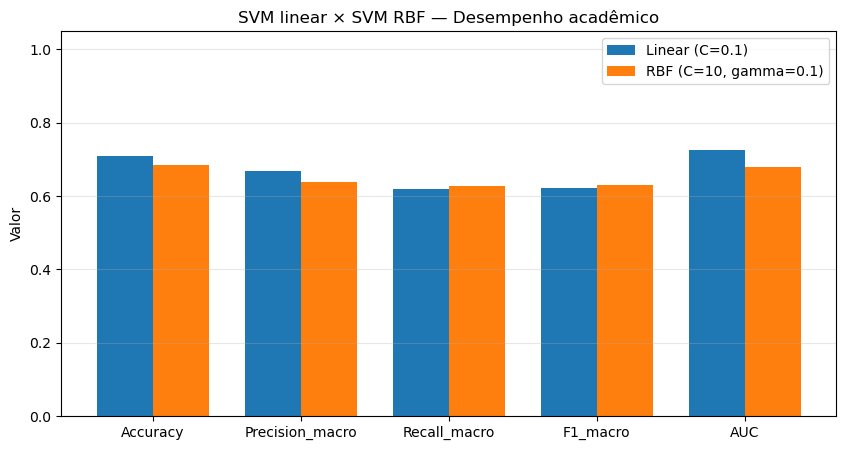

In [19]:
def resumo(nome, pred, score):
    return {
        "Modelo": nome,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "Recall_Aprovado": recall_score(y_test, pred, pos_label=1, zero_division=0),
        "AUC": roc_auc_score(y_test, score),
        "AP": average_precision_score(y_test, score)
    }

comparacao_final = pd.DataFrame([
    resumo(f"Linear (C={C_REAL:g})", y_pred_r, y_score_r),
    resumo(f"RBF (C={C_RBF:g}, gamma={GAMMA_RBF:g})", y_pred_rbf, y_score_rbf)
])

display(comparacao_final.style.format({
    "Accuracy": "{:.4f}", "Precision_macro": "{:.4f}", "Recall_macro": "{:.4f}",
    "F1_macro": "{:.4f}", "Recall_Aprovado": "{:.4f}", "AUC": "{:.4f}", "AP": "{:.4f}"
}))

plt.figure(figsize=(10,5))
metricas_plot = ["Accuracy", "Precision_macro", "Recall_macro", "F1_macro", "AUC"]
x = np.arange(len(metricas_plot))
largura = 0.38
for k, (_, linha) in enumerate(comparacao_final.iterrows()):
    plt.bar(x + (k - 0.5) * largura, [linha[m] for m in metricas_plot], largura, label=linha["Modelo"])
plt.xticks(x, metricas_plot)
plt.ylim(0, 1.05)
plt.ylabel("Valor")
plt.title("SVM linear × SVM RBF — Desempenho acadêmico")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

### Interpretação dos resultados do SVM RBF

Como ler a grade C × gamma (confira com os valores gerados acima):

- **gamma = 10** (e, em menor grau, 1): costuma elevar a acurácia de treino e derrubar a de teste, com muitos vetores de suporte. Esse afastamento treino × teste é o sinal de sobreajuste.
- **gamma = 0,001 com C baixo (0,01 / 0,1)**: a fronteira fica rígida demais; o modelo tende a prever quase só a classe majoritária (acurácia razoável, mas recall da classe "Aprovado" ou "Não aprovado" e F1 macro baixos).
- **C e gamma atuam juntos**: C alto com gamma alto é a combinação mais propensa a sobreajuste; C baixo com gamma baixo, a de subajuste.
- A escolha deve priorizar **F1 macro / recall macro** (classes desbalanceadas) e a **diferença treino × teste**, não apenas a acurácia de teste.
- Se o RBF não superar claramente o linear na tabela de comparação final, isso indica que a fronteira entre aprovados e não aprovados neste conjunto é essencialmente linear, e o kernel mais complexo não compensa.